In [ ]:
# Open Zsun, 0.45, 0.1 Zsun grids
from posydon.grids.psygrid import PSyGrid
from posydon.config import PATH_TO_POSYDON_DATA
from posydon.utils.common_functions import convert_metallicity_to_string, orbital_separation_from_period
from posydon.popsyn.distributions import PowerLawPeriod
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cmap import Colormap
import pickle
from pathlib import Path
from tqdm import tqdm
from scipy.stats import gaussian_kde
tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))

In [2]:
import json

with open('/Users/max/Documents/projects/WR_population/data/observations/Galactic_WRs.json', 'r') as f:
    observational_data = json.load(f)


obs_df = pd.DataFrame.from_dict(observational_data, orient='index')
obs_df.index.name = 'WR_name'

# Unpack [lower, value, upper] list columns into separate _err_lo, _val, _err_hi columns
list_cols = ['Period', 'Eccentricity', 'M1', 'M2', 'Mass Function', 'M1_sin3i', 'M2_sin3i', 'RA', 'Dec']
for col in list_cols:
    if col in obs_df.columns:
        unpacked = pd.DataFrame(obs_df[col].tolist(), index=obs_df.index,
                                columns=[f'{col}_err_lo', col, f'{col}_err_hi'])
        obs_df = obs_df.drop(columns=col).join(unpacked)
LOG_P_MIN, LOG_P_MAX = -1, 6  # shared x-range in log10(P)
OBS_N_BINS = 50             # number of bins for the observations PMF

def plot_observations(obs_df, ax, **kwargs):
    """Plot observed period distribution as a PMF in log10(P) space.
    Multiply KDE evaluations by BIN_WIDTH to put them on the same scale."""
    log_periods = np.log10(obs_df['Period'].dropna().astype(float))
    bins = np.linspace(LOG_P_MIN, LOG_P_MAX, OBS_N_BINS + 1)
    h, edges = np.histogram(log_periods, bins=bins,
                            density=True)
    ax.fill_between(10**edges[:-1], h, step='post', alpha=0.4, color='black',
                    zorder=10, label='MW', edgecolor='none', **kwargs)
    ax.step(10**edges[:-1], h, where='post', color='black', linewidth=1.5,
            zorder=11, alpha=0.6)


In [3]:
LMC_observations = pd.read_csv("/Users/max/Documents/projects/WR_population/data/observations/LMC_WRs.csv", sep=",")

# Drop specific BAT99 values
bat99_to_drop = [6, 12, 27, 33, 42, 59, 68, 77, 80, 92, 93, 97, 98, 99, 102, 104, 105, 106, 107, 108, 109, 110, 112, 113, 114, 116, 117, 118, 119, 126]
LMC_observations = LMC_observations[~LMC_observations['BAT99'].isin(bat99_to_drop)]
obs_single = ~(LMC_observations['Binary?'] != '-')
binary_P_mask = ~obs_single & (LMC_observations['P [d]'] != '-')

print(LMC_observations['P [d]'][binary_P_mask].values)

def plot_observations_LMC(ax):
    
    LMC_observations = pd.read_csv("/Users/max/Documents/projects/WR_population/data/observations/LMC_WRs.csv", sep=",")

    # Drop specific BAT99 values
    bat99_to_drop = [6, 12, 27, 33, 42, 59, 68, 77, 80, 92, 93, 97, 98, 99, 102, 104, 105, 106, 107, 108, 109, 110, 112, 113, 114, 116, 117, 118, 119, 126]
    LMC_observations = LMC_observations[~LMC_observations['BAT99'].isin(bat99_to_drop)]
    obs_single = ~(LMC_observations['Binary?'] != '-')
    binary_P_mask = ~obs_single & (LMC_observations['P [d]'] != '-')
    h, edges = np.histogram(np.log10(LMC_observations['P [d]'][binary_P_mask].astype(float)),
                            bins = np.linspace(LOG_P_MIN, LOG_P_MAX, 41),
                            density = True  
                                     )
    ax.fill_between(10**edges[:-1],
                    h,
                    step='post', 
                    alpha=0.5,
                    zorder=10,
                    label='LMC', color=tol_vibrant[4], edgecolor='none')
    ax.step(10**edges[:-1], h, where='post', color=tol_vibrant[4], linewidth=1,
            zorder=11, alpha=0.6)
    
def plot_observations_SMC(ax):
    
    SMC_observations = pd.read_csv("/Users/max/Documents/projects/WR_population/data/observations/SMC_WRs.data", sep=",")

    h, edges = np.histogram(np.log10(SMC_observations['binary_period[days]'][~pd.isna(SMC_observations['binary_period[days]'])].astype(float)),
                            bins = np.linspace(LOG_P_MIN, LOG_P_MAX, 41),
                            density = True  
                                     )
    ax.fill_between(10**edges[:-1],
                    h,
                    step='post',
                    alpha=0.5,
                    zorder=10,
                    label='SMC', color=tol_vibrant[0], edgecolor='none')
    ax.step(10**edges[:-1], h, where='post', color=tol_vibrant[0], linewidth=1.5,
            zorder=11, alpha=0.6)

['17.99' '2.20' '1.90' '2.82' '31.69' '37.59' '5.21' '2.11' '2.75' '2.77']


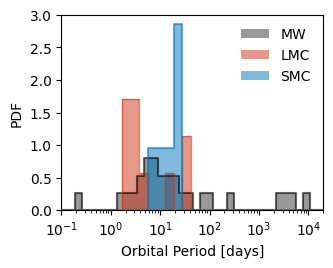

In [7]:
fig, ax = plt.subplots(1,1, figsize=(3.38, 2.535))

plot_observations(obs_df, ax)
# Plot LMC and SMC data
plot_observations_LMC(ax)
plot_observations_SMC(ax)

ax.set_ylim(0, 3)
ax.set_xlim(1e-1, 2e4)

ax.set_xscale('log')
ax.set_xlabel('Orbital Period [days]')
ax.set_ylabel('PDF')

ax.legend(frameon=False)
plt.savefig('figures/pdf/observed_period_distributions.pdf',  bbox_inches='tight')
plt.savefig('figures/png/observed_period_distributions.png',  bbox_inches='tight')